<a href="https://colab.research.google.com/github/22f2000792/22f2000792.github.io/blob/main/MLP_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [136]:
import numpy as np
import pandas as pd

In [137]:
train_df=pd.read_csv('/content/drive/MyDrive/mlp project/train.csv')

In [138]:
test_df=pd.read_csv('/content/drive/MyDrive/mlp project/test.csv')

In [139]:
train_df.head(3)

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2


In [140]:
test_df.head(3)

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_support,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro
0,0,Praklar,2.0,11.0,2.0,11.0,unverified_operator,t,29.0,t,...,9.82,9.16,9.6,unlicensed,29,29,0,0,3.97,MTR-07
1,1,Draren,2.0,6.0,2.0,2.0,unverified_operator,f,8.0,t,...,NaN,NaN,NaN,licensed,8,1,7,0,NaN,MTR-13
2,2,Sinnovara,3.0,4.0,3.0,3.0,managed_operator,f,33.0,t,...,10.00,10.00,10.0,licensed,33,33,0,0,0.27,MTR-16


## Shape of train and test

In [141]:
train_df.shape,test_df.shape

((279746, 60), (114538, 59))

In [142]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  object 
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  object 
 7   operator_certified            279142 non-null  object 
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  object 
 10  operator_id_verified          279142 non-null  object 
 11  zone                          279746 non-null  object 
 12  borough                       65295 non-null

## No of total NaN


In [143]:
train_df.isnull().sum().sum()

np.int64(859743)

## Missing Value and percentage of missing-value of each Column's

In [144]:
missing_counts = train_df.isnull().sum()
missing_cols = missing_counts[missing_counts > 0]
percentage=train_df.isnull().mean()*100
perce_=percentage[percentage>0]

missing_value = pd.DataFrame({
    'Missing Values': missing_cols,
    'Percentage':perce_,
    'Data Type': train_df[missing_cols.index].dtypes
})

missing_value

,Missing Values,Percentage,Data Type
operator_ref,604,0.215910,object
operator_platform_age_years,604,0.215910,float64
operator_platform_age_months,604,0.215910,float64
operator_active_years,606,0.216625,float64
operator_active_months,606,0.216625,float64
operator_certified,604,0.215910,object
operator_portfolio_size,604,0.215910,float64
operator_has_avatar,604,0.215910,object
operator_id_verified,604,0.215910,object
borough,214451,76.659184,object


## No of column's that contains missing value

In [145]:
len(missing_counts[missing_counts > 0])

30

## Categorical column's that contains missing value

In [146]:
missing_value[missing_value['Data Type']=='object']

,Missing Values,Percentage,Data Type
operator_ref,604,0.215910,object
operator_certified,604,0.215910,object
operator_has_avatar,604,0.215910,object
operator_id_verified,604,0.215910,object
borough,214451,76.659184,object
bookable,97,0.034674,object
first_review_date,54240,19.389017,object
last_review_date,54240,19.389017,object


In [147]:
missing_value[missing_value['Data Type']=='object'].shape

(8, 3)

In [148]:
missing_value[missing_value['Data Type']=='float64'].shape

(22, 3)

## Total Missing value in float,int,object column's

In [ ]:
# Group by data type and sum the missing values
train_df.isnull().sum().groupby(train_df.dtypes).sum()



,0
int64,0
float64,534299
object,325444


## Percentage of missing value in column's(int/float/object)

In [ ]:
train_df.isnull().mean().groupby(train_df.dtypes).sum()

,0
int64,0.000000
float64,1.909943
object,1.163355


Inconsistent Range

## Checking for Invalid value in int/float column

In [153]:
# checking for total invalid value for numerical/float column
for col in train_df.select_dtypes(exclude=object):
    print(f'{col}:{train_df[col].apply(lambda x: isinstance(x, str)).sum()}')

space_id:0
operator_platform_age_years:0
operator_platform_age_months:0
operator_active_years:0
operator_active_months:0
operator_portfolio_size:0
geo_lat:0
geo_lon:0
max_seats:0
utility_rooms:0
zones:0
workstations:0
min_term_days:0
max_term_days:0
min_term_floor:0
min_term_ceiling:0
max_term_floor:0
max_term_ceiling:0
min_term_avg:0
max_term_avg:0
open_slots_a:0
open_slots_b:0
open_slots_c:0
open_slots_d:0
review_count:0
review_count_12m:0
review_count_30d:0
open_slots_e:0
review_count_prev_yr:0
booked_load:0
score_overall:0
score_accuracy:0
score_condition:0
score_onboarding:0
score_support:0
score_access:0
score_value:0
operator_metro_units:0
operator_metro_whole:0
operator_metro_private:0
operator_metro_shared:0
reviews_per_month:0
price_tier:0


## Checking for total invalid value in object column

In [154]:
# checking for total invalid value for non-numerical column
for col in train_df.select_dtypes(include=object):
    print(f'{col}:{train_df[col].apply(lambda x: isinstance(x, int)).sum()}')

operator_ref:0
operator_class:0
operator_certified:0
operator_has_avatar:0
operator_id_verified:0
zone:0
borough:0
space_class:0
access_type:0
facilities:0
snapshot_start_date:0
snapshot_end_date:0
bookable:0
first_review_date:0
last_review_date:0
compliance_status:0
metro:0


## Checking for unique value for object column's

In [160]:
for col in train_df.select_dtypes(include=object):
    print(f'{col}\n : unique {train_df[col].unique()}')
    print("=========="*50)

operator_ref
 : unique ['Bralchu' 'Grorfian' 'Snelenr' ... 'Prenzill' 'Shiansputa' 'Drynba']
operator_class
 : unique ['independent_operator' 'unverified_operator' 'managed_operator']
operator_certified
 : unique ['f' 't' nan]
operator_has_avatar
 : unique ['t' 'f' nan]
operator_id_verified
 : unique ['t' 'f' nan]
zone
 : unique ['ZN-0557' 'ZN-0082' 'ZN-0654' ... 'ZN-1141' 'ZN-0193' 'ZN-1098']
borough
 : unique [nan 'BRG-18' 'BRG-45' 'BRG-14' 'BRG-31' 'BRG-30' 'BRG-22' 'BRG-54'
 'BRG-43' 'BRG-21' 'BRG-41' 'BRG-12' 'BRG-34' 'BRG-10' 'BRG-20' 'BRG-24'
 'BRG-15' 'BRG-26' 'BRG-48' 'BRG-36' 'BRG-55' 'BRG-47' 'BRG-19' 'BRG-01'
 'BRG-44' 'BRG-52' 'BRG-33' 'BRG-29' 'BRG-51' 'BRG-39' 'BRG-16' 'BRG-32'
 'BRG-03' 'BRG-49' 'BRG-28' 'BRG-38' 'BRG-23' 'BRG-05' 'BRG-17' 'BRG-27'
 'BRG-07' 'BRG-42' 'BRG-35' 'BRG-13' 'BRG-04' 'BRG-02' 'BRG-11' 'BRG-08'
 'BRG-37' 'BRG-46' 'BRG-40' 'BRG-09' 'BRG-53' 'BRG-25' 'BRG-06' 'BRG-50']
space_class
 : unique ['Boutique Workroom' 'Ground Bay' 'Flex Bay' 'Enclosed A

## Checking for min and max value for Column's(int/float)
>Generally non-negative value can't exist in numerical column

In [163]:
for col in train_df.select_dtypes(exclude=object):
    print(f'{col} : min :{train_df[col].min()}  max :{train_df[col].max()},less than zero found:{train_df[col].min()<0}')

space_id : min :0  max :279745,less than zero found:False
operator_platform_age_years : min :0.0  max :17.0,less than zero found:False
operator_platform_age_months : min :0.0  max :11.0,less than zero found:False
operator_active_years : min :0.0  max :15.0,less than zero found:False
operator_active_months : min :0.0  max :11.0,less than zero found:False
operator_portfolio_size : min :0.0  max :5978.0,less than zero found:False
geo_lat : min :-4.818000000000005  max :111.768,less than zero found:True
geo_lon : min :-123.7498  max :87.04520000000001,less than zero found:True
max_seats : min :1  max :16,less than zero found:False
utility_rooms : min :0.5  max :50.0,less than zero found:False
zones : min :0.0  max :50.0,less than zero found:False
workstations : min :1.0  max :60.0,less than zero found:False
min_term_days : min :1.0  max :365.0,less than zero found:False
max_term_days : min :1.0  max :577341108.0,less than zero found:False
min_term_floor : min :1.0  max :365.0,less than zer

## Statistical description of object Column

In [ ]:
train_df.describe(include=object)

,operator_ref,operator_class,operator_certified,operator_has_avatar,operator_id_verified,zone,borough,space_class,access_type,facilities,snapshot_start_date,snapshot_end_date,bookable,first_review_date,last_review_date,compliance_status,metro
count,279142,279746,279142,279142,279142,279746,65295,279746,279746,279746,279746,279746,279649,225506,225506,279746,279746
unique,41903,3,2,2,2,1380,55,131,4,251649,383,384,2,5342,3287,4,16
top,Bessstu,unverified_operator,f,t,t,ZN-0923,BRG-18,Ground Bay,whole_unit,"[""FCL-012"", ""FCL-104"", ""FCL-058"", ""FCL-085"", ""...",2024-08-25,2024-08-26,t,2024-06-30,2024-06-30,unlicensed,MTR-09
freq,1467,127473,180235,267462,275236,10990,10670,151306,211010,361,14746,12773,277713,695,11631,154603,35746


In [ ]:
train_df.describe(exclude=object)

,space_id,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_portfolio_size,geo_lat,geo_lon,max_seats,utility_rooms,...,score_onboarding,score_support,score_access,score_value,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,price_tier
count,279746.00000,279142.000000,279142.000000,279140.000000,279140.000000,279142.000000,279746.000000,279746.000000,279746.000000,249847.000000,...,225503.000000,225505.000000,225501.000000,225500.000000,279746.000000,279746.000000,279746.000000,279746.000000,225506.000000,279746.000000
mean,139872.50000,6.794735,5.453275,5.083295,5.298635,49.472043,77.766908,-35.144810,3.627312,1.358645,...,9.633323,9.651561,9.559088,9.302167,22.630883,18.468203,3.905736,0.098940,1.528739,2.482316
std,80755.85854,4.187652,3.489590,4.040029,3.480848,332.752235,37.513760,57.170057,2.277564,0.806307,...,0.750909,0.772645,0.718961,0.915583,58.731714,54.515981,19.515136,1.370754,1.808781,1.109886
min,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,-4.818000,-123.749800,1.000000,0.500000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000,1.000000
25%,69936.25000,3.000000,2.000000,2.000000,2.000000,1.000000,68.041500,-76.559800,2.000000,1.000000,...,9.600000,9.620000,9.420000,9.120000,1.000000,1.000000,0.000000,0.000000,0.340000,2.000000
50%,139872.50000,7.000000,5.000000,4.000000,5.000000,4.000000,94.623000,-31.132600,3.000000,1.000000,...,9.840000,9.880000,9.760000,9.520000,3.000000,2.000000,0.000000,0.000000,1.000000,2.000000
75%,209808.75000,10.000000,9.000000,8.000000,8.000000,19.000000,100.941000,-21.265600,4.000000,1.500000,...,10.000000,10.000000,10.000000,9.800000,15.000000,10.000000,1.000000,0.000000,2.190000,4.000000
max,279745.00000,17.000000,11.000000,15.000000,11.000000,5978.000000,111.768000,87.045200,16.000000,50.000000,...,10.000000,10.000000,10.000000,10.000000,754.000000,754.000000,233.000000,62.000000,150.180000,4.000000


In [ ]:
train_df[train_df.duplicated()].shape[0],test_df[test_df.duplicated()].shape[0]

(0, 0)

In [ ]:
from scipy.stats import zscore
outlier_val=dict()
for col in train_df.select_dtypes(exclude=object):
    z_score=np.abs(zscore(train_df[col]))
    threshold=3
    outlier=train_df[z_score>threshold]
    outlier_val[col]=outlier.shape[0]
print(outlier_val)



{'space_id': 0, 'operator_platform_age_years': 0, 'operator_platform_age_months': 0, 'operator_active_years': 0, 'operator_active_months': 0, 'operator_portfolio_size': 0, 'geo_lat': 0, 'geo_lon': 0, 'max_seats': 4422, 'utility_rooms': 0, 'zones': 0, 'workstations': 0, 'min_term_days': 0, 'max_term_days': 0, 'min_term_floor': 0, 'min_term_ceiling': 0, 'max_term_floor': 0, 'max_term_ceiling': 0, 'min_term_avg': 6713, 'max_term_avg': 13, 'open_slots_a': 0, 'open_slots_b': 0, 'open_slots_c': 0, 'open_slots_d': 0, 'review_count': 6271, 'review_count_12m': 3572, 'review_count_30d': 3937, 'open_slots_e': 0, 'review_count_prev_yr': 4280, 'booked_load': 0, 'score_overall': 0, 'score_accuracy': 0, 'score_condition': 0, 'score_onboarding': 0, 'score_support': 0, 'score_access': 0, 'score_value': 0, 'operator_metro_units': 6591, 'operator_metro_whole': 5907, 'operator_metro_private': 3730, 'operator_metro_shared': 1414, 'reviews_per_month': 0, 'price_tier': 0}


In [ ]:
pd.DataFrame.from_dict(outlier_val,orient='index',columns=['No of outlier'])

,No of outlier
space_id,0
operator_platform_age_years,0
operator_platform_age_months,0
operator_active_years,0
operator_active_months,0
operator_portfolio_size,0
geo_lat,0
geo_lon,0
max_seats,4422
utility_rooms,0


In [ ]:
train_df

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2
3,3,Spesspe,2.0,1.0,2.0,1.0,unverified_operator,t,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.60,MTR-09,4
4,4,Gosho,2.0,7.0,2.0,4.0,unverified_operator,t,1.0,t,...,9.42,9.74,licensed,1,1,0,0,4.64,MTR-08,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279741,279741,Vukello,8.0,3.0,8.0,3.0,unverified_operator,t,1.0,t,...,9.46,9.64,licensed,1,1,0,0,5.79,MTR-14,2
279742,279742,Sovabax,0.0,4.0,0.0,1.0,unverified_operator,f,1.0,f,...,NaN,NaN,unlicensed,1,1,0,0,NaN,MTR-10,3
279743,279743,Lianune,9.0,2.0,1.0,1.0,unverified_operator,f,1.0,t,...,10.00,8.00,licensed,1,1,0,0,0.19,MTR-13,2
279744,279744,Hynbalrn,3.0,1.0,3.0,1.0,independent_operator,t,4.0,t,...,9.00,9.16,exempt,4,0,4,0,1.36,MTR-03,2


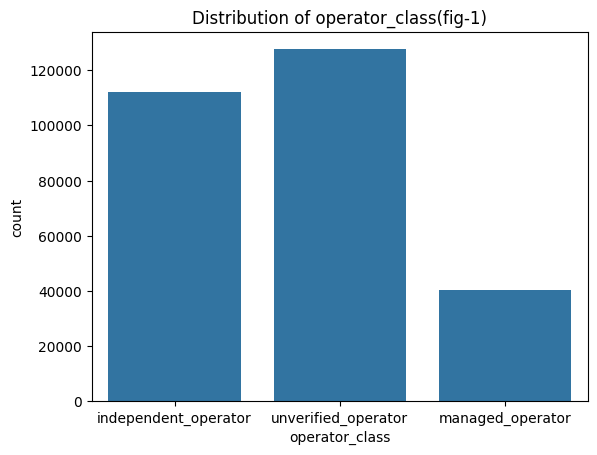

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(train_df,x='operator_class')
plt.title('Distribution of operator_class(fig-1)')
plt.show()

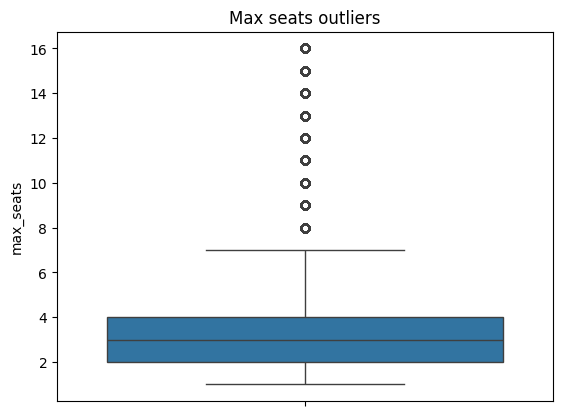

In [ ]:
sns.boxplot(train_df['max_seats'])
plt.title("Max seats outliers")
plt.show()

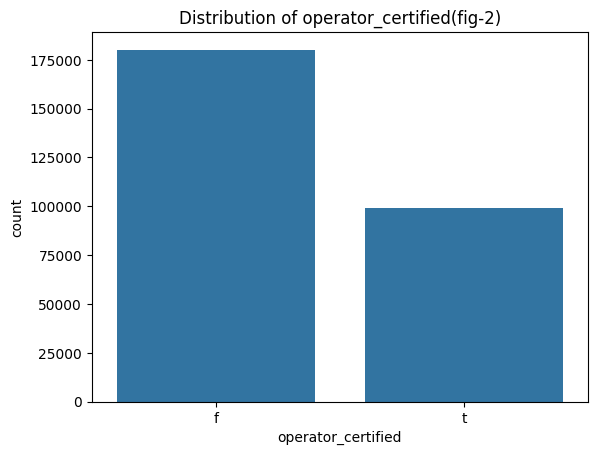

In [ ]:
sns.countplot(train_df,x='operator_certified')
plt.title('Distribution of operator_certified(fig-2)')
plt.show()

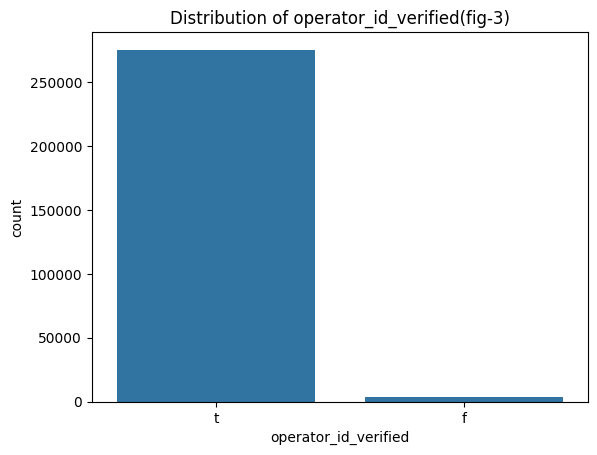

In [ ]:
sns.countplot(train_df,x='operator_id_verified')
plt.title('Distribution of operator_id_verified(fig-3)')
plt.show()

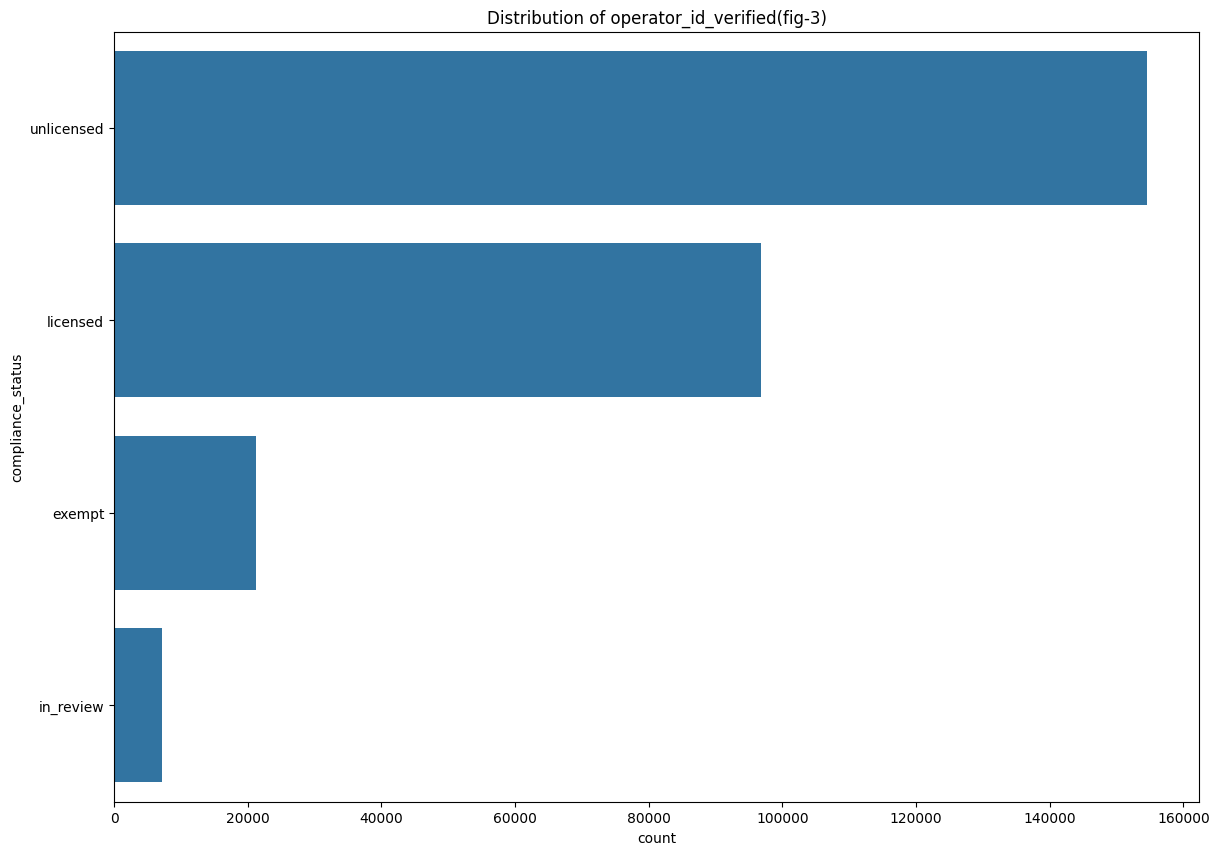

In [ ]:
plt.figure(figsize=(14,10))
sns.countplot(train_df,y='compliance_status')
plt.title('Distribution of operator_id_verified(fig-3)')
plt.show()

In [ ]:
cor=train_df.corr(numeric_only=True)
cor['price_tier'].sort_values(ascending=False)

,price_tier
price_tier,1.000000
max_seats,0.467213
zones,0.371447
workstations,0.339638
geo_lat,0.298701
utility_rooms,0.253952
score_access,0.110951
score_condition,0.081778
operator_metro_whole,0.076327
operator_portfolio_size,0.070470


In [ ]:
cor

,space_id,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_portfolio_size,geo_lat,geo_lon,max_seats,utility_rooms,...,score_onboarding,score_support,score_access,score_value,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,price_tier
space_id,1.000000,-0.000722,-0.001480,-0.002267,0.002358,-0.000340,-0.001989,0.001090,-0.000015,-0.000715,...,0.001179,0.000679,0.000517,0.002376,-0.000161,-0.000248,-0.000244,0.000912,-0.001557,0.001842
operator_platform_age_years,-0.000722,1.000000,-0.036264,0.764573,0.005784,-0.044270,-0.014607,-0.114595,-0.004305,0.038587,...,0.092637,0.083873,0.084313,0.074053,-0.031178,0.000911,-0.089560,-0.025804,-0.106938,0.066376
operator_platform_age_months,-0.001480,-0.036264,1.000000,-0.013881,0.447666,-0.049666,-0.005462,-0.005173,0.001471,-0.004092,...,0.004285,0.004116,-0.003092,0.001626,-0.043304,-0.042191,-0.013554,0.020665,0.002173,-0.004897
operator_active_years,-0.002267,0.764573,-0.013881,1.000000,-0.021535,0.001738,0.014765,-0.049636,0.012291,0.050096,...,0.030603,0.014682,0.036398,-0.004077,0.067616,0.090666,-0.046342,-0.019572,-0.122344,0.059390
operator_active_months,0.002358,0.005784,0.447666,-0.021535,1.000000,-0.048249,-0.008419,0.002954,0.003697,-0.009841,...,0.009974,0.007703,-0.002959,0.003949,-0.050836,-0.045886,-0.025557,-0.006931,-0.000687,-0.006639
operator_portfolio_size,-0.000340,-0.044270,-0.049666,0.001738,-0.048249,1.000000,0.048825,-0.009950,-0.029969,-0.015058,...,-0.092235,-0.104251,-0.045420,-0.103582,0.533927,0.542359,0.083533,-0.001649,-0.026216,0.070470
geo_lat,-0.001989,-0.014607,-0.005462,0.014765,-0.008419,0.048825,1.000000,-0.034471,-0.005930,-0.036586,...,-0.063242,-0.050154,-0.083246,-0.081552,0.065226,0.060406,0.025595,-0.020646,0.005992,0.298701
geo_lon,0.001090,-0.114595,-0.005173,-0.049636,0.002954,-0.009950,-0.034471,1.000000,0.036803,-0.065487,...,-0.055647,-0.027207,-0.081587,-0.040791,0.077393,0.079746,0.010573,0.013485,-0.019588,-0.047293
max_seats,-0.000015,-0.004305,0.001471,0.012291,0.003697,-0.029969,-0.005930,0.036803,1.000000,0.511669,...,0.019622,0.026038,0.020552,0.028846,-0.002422,0.040634,-0.117579,-0.041592,0.043753,0.467213
utility_rooms,-0.000715,0.038587,-0.004092,0.050096,-0.009841,-0.015058,-0.036586,-0.065487,0.511669,1.000000,...,0.006451,0.003640,0.025882,0.017625,0.028475,0.023417,0.016788,0.054889,-0.033985,0.253952


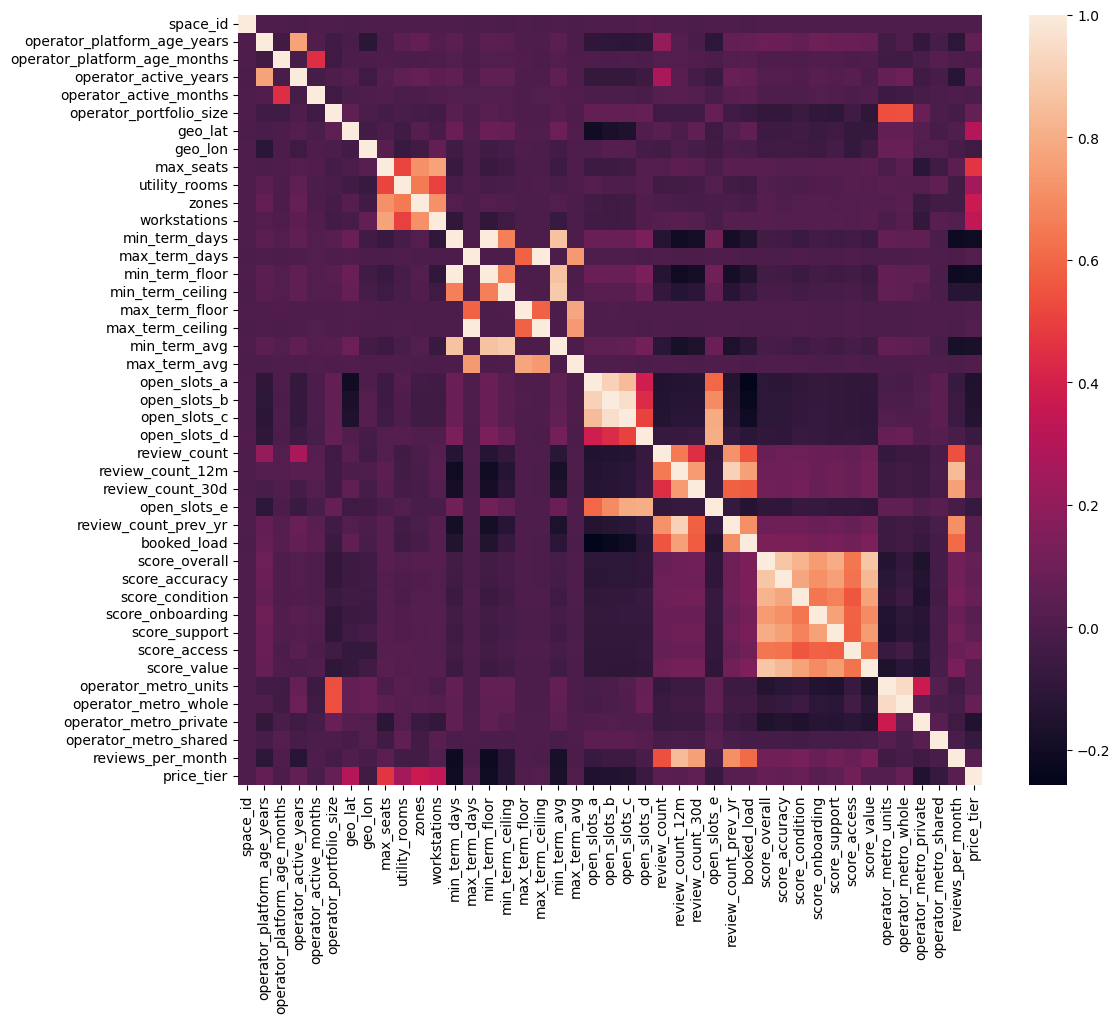

In [ ]:
cor = train_df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(cor)
plt.show()

In [ ]:
train_df_without_id=train_df.drop(columns=['space_id','operator_ref'],axis=1)
test_df_without_id=test_df.drop(columns=['space_id','operator_ref'],axis=1)

In [ ]:
feature=train_df_without_id.drop('price_tier',axis=1)
label=train_df_without_id['price_tier'].copy()

In [ ]:
feature.head(3)

,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,operator_id_verified,zone,...,score_support,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro
0,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,t,ZN-0557,...,9.74,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09
1,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,t,ZN-0082,...,NaN,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01
2,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,t,ZN-0082,...,10.00,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01


In [ ]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
num_cols = feature.select_dtypes(exclude=['object']).columns.tolist()
cat_cols = feature.select_dtypes(include=['object']).columns.tolist()

num_imputer = SimpleImputer(strategy='mean')
feature_num_imputed = pd.DataFrame(num_imputer.fit_transform(feature[num_cols]), columns=num_cols, index=feature.index)
test_num_imputed = pd.DataFrame(num_imputer.transform(test_df_without_id[num_cols]), columns=num_cols, index=test_df_without_id.index)

# first encoding cat col with ordinal enc then imputing with SimpleImputer
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan)
feature_cat_encoded = pd.DataFrame(encoder.fit_transform(feature[cat_cols]), columns=cat_cols, index=feature.index)
test_cat_encoded = pd.DataFrame(encoder.transform(test_df_without_id[cat_cols]), columns=cat_cols, index=test_df_without_id.index)

cat_imputer = SimpleImputer(strategy='most_frequent')
feature_cat_imputed = pd.DataFrame(cat_imputer.fit_transform(feature_cat_encoded), columns=cat_cols, index=feature.index)
test_cat_imputed = pd.DataFrame(cat_imputer.transform(test_cat_encoded), columns=cat_cols, index=test_df_without_id.index)

#combining data
feature_imputed_clean = pd.concat([feature_num_imputed, feature_cat_imputed], axis=1)
test_imputed_clean = pd.concat([test_num_imputed, test_cat_imputed], axis=1)

print("missing values in feature:", feature_imputed_clean.isnull().sum().sum())
print("missing values in test:", test_imputed_clean.isnull().sum().sum())

Remaining missing values in train: 0
Remaining missing values in test: 0


In [ ]:
scaler = RobustScaler(quantile_range=(25.0, 75.0))

# 1. Scale training numeric features and convert the output NumPy array back to a DataFrame
feature_imputed_clean_scaled = pd.DataFrame(
    scaler.fit_transform(feature_imputed_clean[num_cols]),
    columns=num_cols,
    index=feature.index
)

# 2. Scale test numeric features and convert back to a DataFrame
test_imputed_clean_scaled = pd.DataFrame(
    scaler.transform(test_imputed_clean[num_cols]),
    columns=num_cols,
    index=test_imputed_clean.index
)

In [ ]:
from sklearn.preprocessing import RobustScaler
scaler=RobustScaler(quantile_range=(25.0,75.0))
feature_imputed_clean_scaled=scaler.fit_transform(feature_imputed_clean[num_cols])
test_imputed_clean_scaled=scaler.transform(test_imputed_clean[num_cols])

In [ ]:
feature_imputed_clean_scaled

array([[ 0.71428571,  0.42857143,  0.5       , ...,  2.        ,
         0.        , -0.76811594],
       [-0.71428571, -0.42857143, -0.33333333, ...,  2.        ,
         0.        ,  0.03531793],
       [ 0.42857143,  0.71428571,  0.5       , ...,  0.        ,
         0.        , -1.05072464],
       ...,
       [ 0.28571429, -0.42857143, -0.5       , ...,  0.        ,
         0.        , -0.93478261],
       [-0.57142857, -0.57142857, -0.16666667, ...,  4.        ,
         0.        , -0.08695652],
       [ 0.28571429,  0.28571429,  0.33333333, ...,  0.        ,
         0.        , -1.        ]])

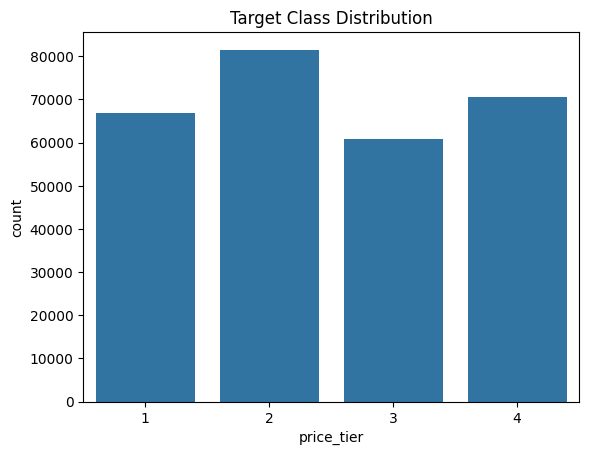

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=label)
plt.title('Target Class Distribution')
plt.show()

In [ ]:
print(label.value_counts(normalize=True) * 100)

price_tier
2    29.144295
4    25.197143
1    23.910619
3    21.747943
Name: proportion, dtype: float64


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler,RobustScaler,OrdinalEncoder
from sklearn.compose import ColumnTransformer,make_column_selector
from sklearn.pipeline import Pipeline
cat_pipe=Pipeline([
    ('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=np.nan)),
    ('cat_impute',SimpleImputer(strategy='most_frequent'))
])
num_pipe=Pipeline([
    ('num_enc',SimpleImputer(strategy='mean')),
    ('num_sca',RobustScaler(quantile_range=(25.0,75.0)))
])

In [ ]:
transformer=ColumnTransformer([
    ('cat_trans',cat_pipe,make_column_selector(dtype_include=np.object_)),
    ('num_trans',num_pipe,make_column_selector(dtype_include=np.float64))
],remainder='passthrough',verbose_feature_names_out=False).set_output(transform='pandas')


In [ ]:
feature_trans=transformer.fit_transform(feature)
test_df_trans=transformer.transform(test_df_without_id)

In [ ]:
from sklearn.model_selection import train_test_split,StratifiedKFold
X_train,X_test,y_train,y_test=train_test_split(feature_trans,label,test_size=0.2,random_state=42,shuffle=True)
print(X_train.shape,y_train.shape)
print(X_test.shape,y_test.shape)

(223796, 57) (223796,)
(55950, 57) (55950,)


In [ ]:
from sklearn.metrics import f1_score
model_score=dict()

In [ ]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression(max_iter=1000,random_state=42)

In [ ]:
lr.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
lr.predict(X_test)

array([2, 4, 4, ..., 4, 1, 2])

In [ ]:
f1_score(y_test,lr.predict(X_test),average='micro')

0.3334763181411975

In [ ]:
from sklearn.dummy import DummyClassifier

# Create a baseline dummy classifier that always predicts the most frequent class
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)

# Predict and calculate baseline Micro F1-score
dummy_preds = dummy_clf.predict(X_test)
baseline_f1 = f1_score(y_test, dummy_preds, average='micro')
model_score['DummyClassifier'] = baseline_f1

print(f"Dummy Classifier (Baseline) Micro F1 Score: {baseline_f1:.4f}")

Dummy Classifier (Baseline) Micro F1 Score: 0.2918


In [ ]:
train_df['price_tier'].unique()

array([2, 1, 4, 3])

In [ ]:
train_df['price_tier'].value_counts()

,count
price_tier,
2,81530
4,70488
1,66889
3,60839


In [ ]:
np.argmax(lr.coef_[0]),np.argmin(lr.coef_[0])

(np.int64(10), np.int64(54))

In [ ]:
print(lr.coef_[0])

[-2.49008638e-05 -5.55542312e-06 -1.01512576e-06 -1.83685842e-07
 -4.40096589e-04 -1.89695214e-04  3.85171111e-05 -1.63254907e-04
  2.68301621e-07  1.10670872e-03  3.80507727e-03  1.06487400e-06
 -6.54801972e-05 -9.73358621e-05  9.55610216e-05  1.94632082e-04
 -1.85643091e-05  1.44002885e-06 -1.42526266e-05  4.43997860e-07
 -3.85660895e-04 -2.15021166e-04  3.67302487e-05 -1.06041741e-04
 -1.24614329e-04 -1.10335765e-04  8.77652732e-04  1.51364559e-04
  8.77652732e-04  4.83654699e-04  1.33701244e-03  1.51364559e-04
  6.70211496e-04 -1.46008291e-04 -4.76954300e-05 -4.78689081e-05
 -6.42570245e-05 -2.27557964e-05 -4.03476519e-05 -7.23582548e-05
 -4.02823122e-06 -1.44487766e-05 -4.73265884e-04  9.78611857e-04
  1.64454341e-03  2.09611048e-03  1.62293984e-03 -1.06018193e-03
 -2.25928182e-04 -6.07293727e-05  1.30544619e-03 -2.55665703e-04
 -5.29449647e-04 -9.60412195e-05 -2.04324845e-03  1.90091411e-03
  9.22736107e-05]


In [ ]:
# 1. Find the index of the highest coefficient for class 0
best_feature_index = lr.coef_[0].argmax()

# 2. Look up the actual feature name using that index
best_feature_name = X_train.columns[best_feature_index]
best_coef_value = lr.coef_[0][best_feature_index]

print(f"Most important feature for Class 0: {best_feature_name}")
print(f"Coefficient value: {best_coef_value}")

Most important feature for Class 0: snapshot_end_date
Coefficient value: 0.0038050772729209077


In [ ]:
X_train.columns[lr.coef_[0].argmin()]

'operator_metro_whole'

In [ ]:
X_train.isnull().sum()

,0
operator_class,0
operator_certified,0
operator_has_avatar,0
operator_id_verified,0
zone,0
borough,0
space_class,0
access_type,0
facilities,0
snapshot_start_date,0


In [ ]:
import pandas as pd
import numpy as np

def check_type_inconsistencies(df, name="DataFrame"):
    print(f"=== Checking Inconsistencies for {name} ===")
    has_inconsistencies = False

    # Check object columns for non-string/non-null elements
    for col in df.select_dtypes(include=['object']):
        # Exclude nulls from check
        non_null_series = df[col].dropna()
        non_str_types = non_null_series[non_null_series.apply(lambda x: not isinstance(x, str))]
        if len(non_str_types) > 0:
            has_inconsistencies = True
            print(f"Column '{col}' (object type) has {len(non_str_types)} non-string values.")
            print(f"Unique problematic values/types:", non_str_types.apply(type).unique())
            display(df.loc[non_str_types.index, [col]].head(5))

    # Check numeric columns for non-numeric/non-float elements
    for col in df.select_dtypes(exclude=['object']):
        non_numeric = df[col].dropna().apply(lambda x: not isinstance(x, (int, float, np.integer, np.floating)))
        if non_numeric.any():
            has_inconsistencies = True
            problem_rows = df[col].dropna()[non_numeric]
            print(f"Column '{col}' (numeric type) has {len(problem_rows)} non-numeric values.")
            display(df.loc[problem_rows.index, [col]].head(5))

    if not has_inconsistencies:
        print("No mixed or inconsistent data types found within the columns!")

check_type_inconsistencies(train_df, "train_df")
check_type_inconsistencies(test_df, "test_df")